# Can we predict whether a transaction is fraud?

**INITIAL PROMPT**: Use this data to perform and EDA analysis, answering the question of "Can we predict if a transaction is a fraud?". You do not have to do any of the machine learning and model prediction, just the EDA. You will need to wrangle the data, visualize its distributions and include bivariate visualizations and relevant scatter plots. You will do this analysis in a interactive python notebook.

**AI Agent:** ChatGPT 6 Luna

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

**Prompt:** “For the Loading in the Data section rename it to just Load the Data. The only outputs that should be shown are a head() of the raw dataset, the shape of the dataset and the statistical description of each column.”

**AI Agent:** ChatGPT 6 Luna

## Load the Data

The CSV is loaded and validated, then the raw data preview, dataset shape, and descriptive statistics are displayed.

In [2]:
data_path = Path.cwd() / "card_transdata.csv"
df_raw = pd.read_csv(data_path)

display(df_raw.head())
print(df_raw.shape)
display(df_raw.describe())

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
1,10.829943,0.175592,1.294219,1.0,NaN,0.0,0.0,0
2,5.091079,NaN,0.427715,1.0,0.0,0.0,1.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0


(999, 8)


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
count,999.000000,996.000000,997.000000,992.000000,995.000000,997.000000,995.000000,999.000000
mean,26.876607,5.437319,1.655069,0.892137,0.313568,0.117352,0.673367,0.079079
std,63.899697,35.668094,2.351386,0.310364,0.464176,0.322001,0.469218,0.269997
min,0.104184,0.001448,0.016933,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.990543,0.306441,0.468123,1.000000,0.000000,0.000000,0.000000,0.000000
50%,10.340321,0.958539,0.955504,1.000000,0.000000,0.000000,1.000000,0.000000
75%,25.393952,3.137259,1.922025,1.000000,1.000000,0.000000,1.000000,0.000000
max,965.910612,990.070315,36.074366,1.000000,1.000000,1.000000,1.000000,1.000000


**Prompt:** “For the Data Wrangling sections, change the title to just Data Wrangling (you can remove the numbers from each section title). First you should check for missing values. Then explain that we will remove all rows with missing values and why. Then do that with code. And then just display the first few rows of the cleaned dataframe. That's all that needs to be in there. Everything else can get removed.”

**AI Agent:** ChatGPT 6 Luna

## Data Wrangling

In [3]:
df_raw.isna().sum()

distance_from_home                0
distance_from_last_transaction    3
ratio_to_median_purchase_price    2
repeat_retailer                   7
used_chip                         4
used_pin_number                   2
online_order                      4
fraud                             0
dtype: int64

There are missing values in only 22 of the 999 rows (about 2.2%). We will remove every row with one or more missing values so all subsequent analysis uses complete transactions. Because this is a small share of the dataset, dropping these rows leaves 977 transactions for analysis.

In [4]:
df = df_raw.dropna().copy()
display(df.head())

,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0
5,5.586408,13.261073,0.064768,1.0,0.0,0.0,0.0,0
6,3.724019,0.956838,0.278465,1.0,0.0,0.0,1.0,0


**Prompt:** “Let's change 3. heading to "Visualize the Data." I do not need the table summary. The first graph is good, just rename it to "Fraud Class Distribution." Then add another graph that visualizes the used pin distribution (name it that), and another one that visualizes the repeat retailer distribution and another one for the online orders distribution. Finally visualize the ratio to median purchase price distribution with a histogram plot. Keep all graphs very simple and bare bones. You do not need to relabel axis or change the visualization in any way other than changing the graph title.”

**AI Agent:** ChatGPT 6 Luna

## Visualize the Data

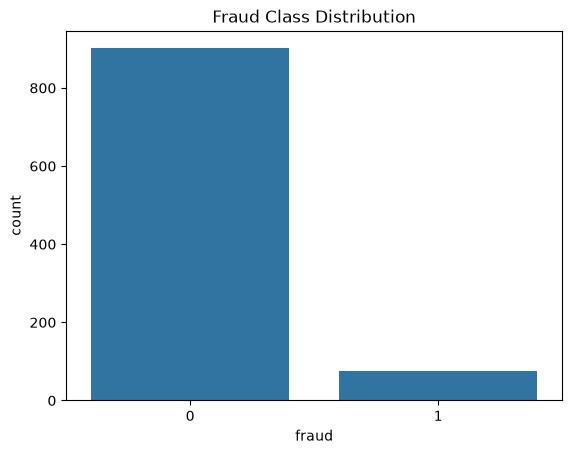

In [5]:
sns.countplot(data=df, x="fraud")
plt.title("Fraud Class Distribution")
plt.grid(False)
plt.show()

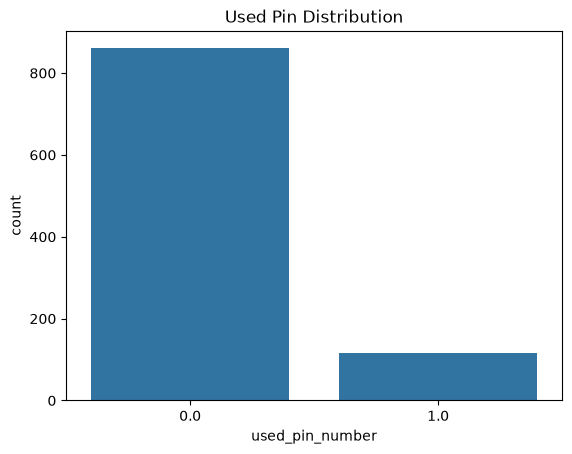

In [6]:
sns.countplot(data=df, x="used_pin_number")
plt.title("Used Pin Distribution")
plt.grid(False)
plt.show()

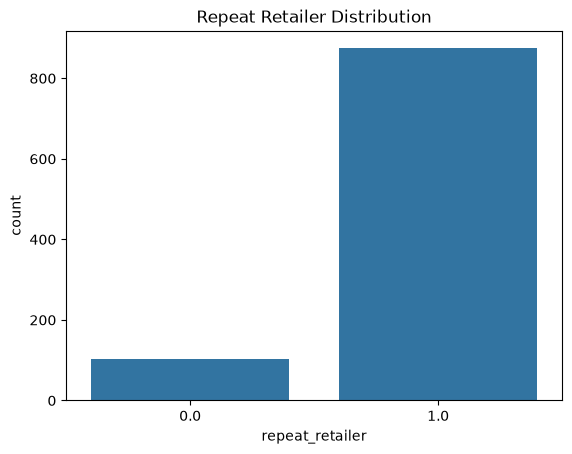

In [7]:
sns.countplot(data=df, x="repeat_retailer")
plt.title("Repeat Retailer Distribution")
plt.grid(False)
plt.show()

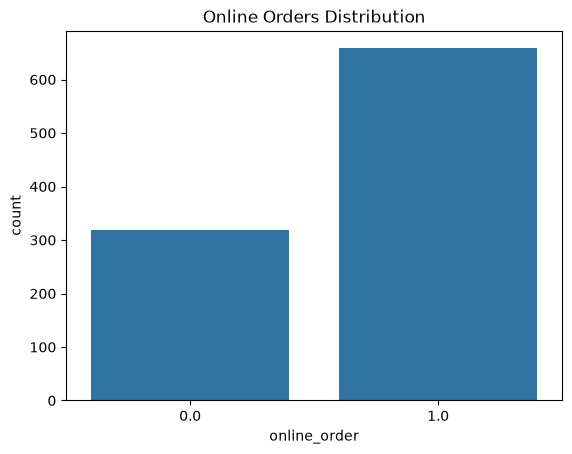

In [8]:
sns.countplot(data=df, x="online_order")
plt.title("Online Orders Distribution")
plt.grid(False)
plt.show()

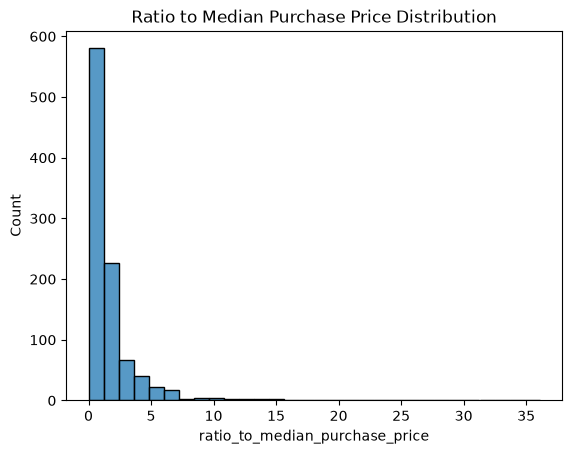

In [9]:
sns.histplot(df["ratio_to_median_purchase_price"], bins=30)
plt.title("Ratio to Median Purchase Price Distribution")
plt.grid(False)
plt.show()

**Prompt:** “Ok moving on to the next section. Rename it to "Better Visualizations: Bivariate Visualizations. This should be the last section, so disregard all other content after that. These next few graphs are going to include a count plot with the variable and a bar plot (make bar plots stacked) of the percentage with whether it was fraudelent or not being the third colored variable (green and red) for both graphs. The first is of transactions with PIN vs Fraudlent Transactions and Percentage of fraudelent transactions with PIN usage. Then I want transactions with chip vs fraudeulent transactions and also percentage of fraudulent transactions with chip usage. And finally transactions with online order vs fraudulent transactions and percentage of fraudlent transactions with online order. At the end of this section, we also have two scatter plots (also with colored fraudulent variables). The first is Distance from last transaction vs ratio to median purchase price. The second one is distance from home vs ratio to median purchase price.”


**AI Agent:** ChatGPT 6 Luna

## Better Visualizations: Bivariate Visualizations

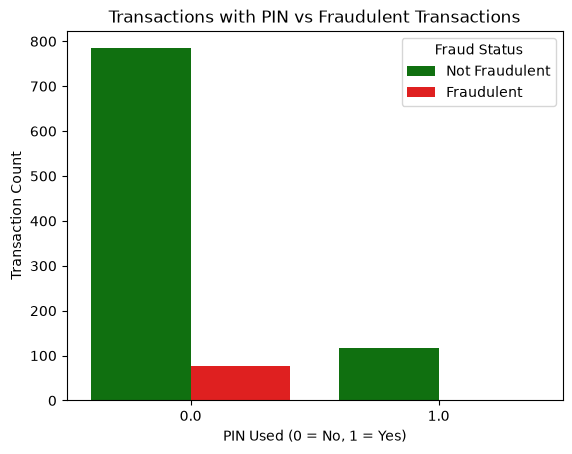

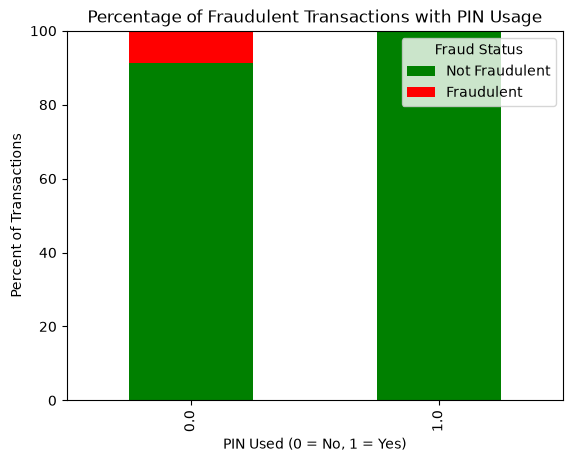

In [10]:
fraud_colors = {0: "green", 1: "red"}

fig, ax = plt.subplots()
sns.countplot(data=df, x="used_pin_number", hue="fraud", hue_order=[0, 1],
              palette=fraud_colors, ax=ax)
ax.set(title="Transactions with PIN vs Fraudulent Transactions", xlabel="PIN Used (0 = No, 1 = Yes)", ylabel="Transaction Count")
ax.legend(title="Fraud Status", labels=["Not Fraudulent", "Fraudulent"])
ax.grid(False)
plt.show()

percentages = pd.crosstab(df["used_pin_number"], df["fraud"], normalize="index")
percentages = percentages.reindex(columns=[0, 1], fill_value=0) * 100
percentages = percentages.rename(columns={0: "Not Fraudulent", 1: "Fraudulent"})
ax = percentages.plot(kind="bar", stacked=True, color=["green", "red"])
ax.set(title="Percentage of Fraudulent Transactions with PIN Usage", xlabel="PIN Used (0 = No, 1 = Yes)", ylabel="Percent of Transactions")
ax.set_ylim(0, 100)
ax.legend(title="Fraud Status")
ax.grid(False)
plt.show()

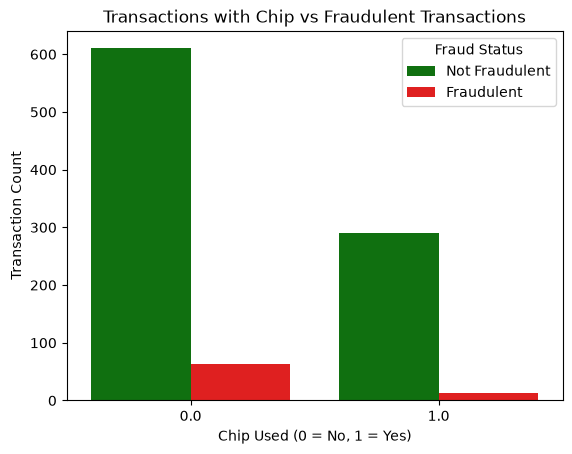

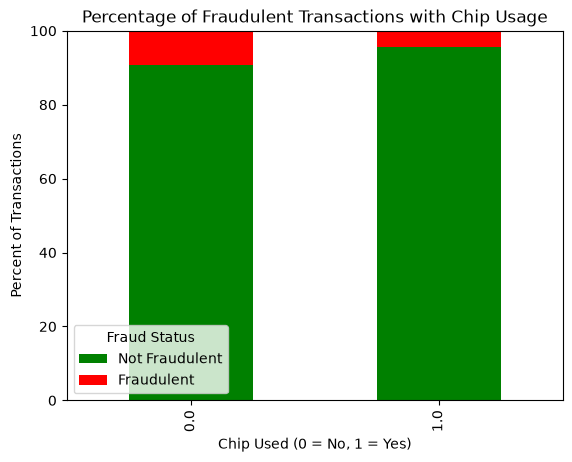

In [11]:
fraud_colors = {0: "green", 1: "red"}

fig, ax = plt.subplots()
sns.countplot(data=df, x="used_chip", hue="fraud", hue_order=[0, 1],
              palette=fraud_colors, ax=ax)
ax.set(title="Transactions with Chip vs Fraudulent Transactions", xlabel="Chip Used (0 = No, 1 = Yes)", ylabel="Transaction Count")
ax.legend(title="Fraud Status", labels=["Not Fraudulent", "Fraudulent"])
ax.grid(False)
plt.show()

percentages = pd.crosstab(df["used_chip"], df["fraud"], normalize="index")
percentages = percentages.reindex(columns=[0, 1], fill_value=0) * 100
percentages = percentages.rename(columns={0: "Not Fraudulent", 1: "Fraudulent"})
ax = percentages.plot(kind="bar", stacked=True, color=["green", "red"])
ax.set(title="Percentage of Fraudulent Transactions with Chip Usage", xlabel="Chip Used (0 = No, 1 = Yes)", ylabel="Percent of Transactions")
ax.set_ylim(0, 100)
ax.legend(title="Fraud Status")
ax.grid(False)
plt.show()

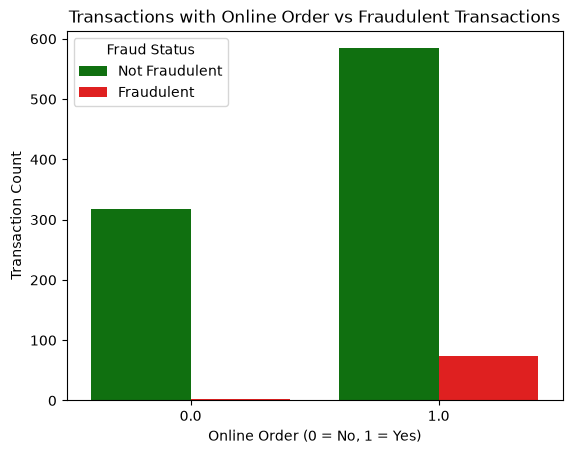

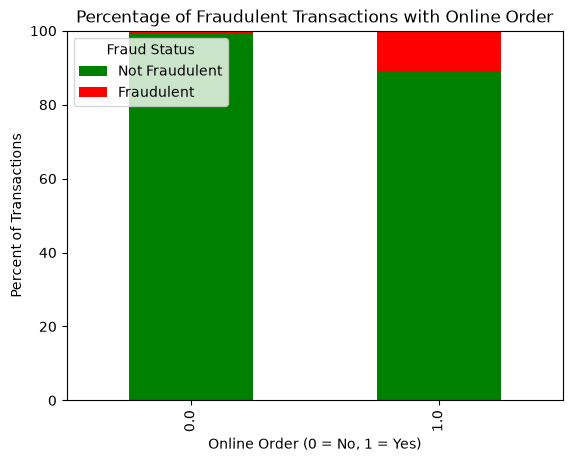

In [12]:
fraud_colors = {0: "green", 1: "red"}

fig, ax = plt.subplots()
sns.countplot(data=df, x="online_order", hue="fraud", hue_order=[0, 1],
              palette=fraud_colors, ax=ax)
ax.set(title="Transactions with Online Order vs Fraudulent Transactions", xlabel="Online Order (0 = No, 1 = Yes)", ylabel="Transaction Count")
ax.legend(title="Fraud Status", labels=["Not Fraudulent", "Fraudulent"])
ax.grid(False)
plt.show()

percentages = pd.crosstab(df["online_order"], df["fraud"], normalize="index")
percentages = percentages.reindex(columns=[0, 1], fill_value=0) * 100
percentages = percentages.rename(columns={0: "Not Fraudulent", 1: "Fraudulent"})
ax = percentages.plot(kind="bar", stacked=True, color=["green", "red"])
ax.set(title="Percentage of Fraudulent Transactions with Online Order", xlabel="Online Order (0 = No, 1 = Yes)", ylabel="Percent of Transactions")
ax.set_ylim(0, 100)
ax.legend(title="Fraud Status")
ax.grid(False)
plt.show()

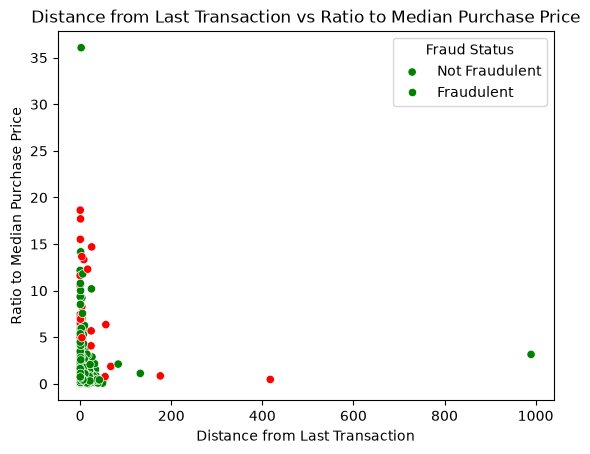

In [13]:
fig, ax = plt.subplots()
sns.scatterplot(
    data=df,
    x="distance_from_last_transaction",
    y="ratio_to_median_purchase_price",
    hue="fraud",
    hue_order=[0, 1],
    palette={0: "green", 1: "red"},
    ax=ax,
)
ax.set(title="Distance from Last Transaction vs Ratio to Median Purchase Price", xlabel="Distance from Last Transaction",
       ylabel="Ratio to Median Purchase Price")
ax.legend(title="Fraud Status", labels=["Not Fraudulent", "Fraudulent"])
ax.grid(False)
plt.show()

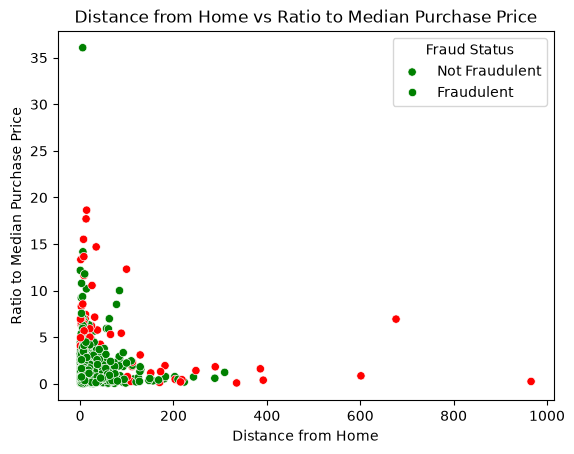

In [14]:
fig, ax = plt.subplots()
sns.scatterplot(
    data=df,
    x="distance_from_home",
    y="ratio_to_median_purchase_price",
    hue="fraud",
    hue_order=[0, 1],
    palette={0: "green", 1: "red"},
    ax=ax,
)
ax.set(title="Distance from Home vs Ratio to Median Purchase Price", xlabel="Distance from Home",
       ylabel="Ratio to Median Purchase Price")
ax.legend(title="Fraud Status", labels=["Not Fraudulent", "Fraudulent"])
ax.grid(False)
plt.show()